In [17]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 2/13/2022
# version ='1.0'

# Demo: Further experiments on Solving Minimum Length Piecewise-Linear Curve Subject to Equality Constraints

In the text book book-convex-2004, section 10.4, the problem of finding the minimum length piecewise-linear curve subject to equality constraints was discussed,
$$
\begin{array}{rcl}
\text{minimize} & & f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}} \\
\text{subject to} & & Ax=b \\
\end{array}
$$
where $x\in R^n$ and $A\in R^{m\times n}$. In practice, the problem is equivalent in finding the minimum length curve in $R^2$ with the knot points (0,0), (1, $x_1$), ..., (n, $x_n$) that satisfy the equality constraints $Ax=b$. 

Some experiments on solving the above problem using the infeasible start Newton method has been reviewed in another article using the following two methods.
\begin{itemize}
\item \textbf{method-I}: using the infeasible start Newton method
\item \textbf{method-II}: using the feasible start Newton method (of which the start point may be from the infeasible start Newton method)
\end{itemize}

For the method-I using the infeasible start Newton method, in the experiment, it is to use a primal feasible start point $x_0$, but it is still found that, the infeasible start Newton method may be broken due to singularity of the KKT matrix, or due to too too small step in the primal dual search direction.

In this demo, a figure from an experiment result when $m=2, n=100$ will show that, the method-I will not converge (even though it is started with a primal feasible point), but the method-II converges as expected.


 In this demo, further experiments are simulated to further compare the above two methods with fixed $m=4$ and $n=10, 50, 100, 500, 1000$ and more. In the experiment, when $n$ is increasing but less than 500, the method-I can still achieve convergence but with a much slower convergence speed than that in method-II. When $n$ is larger than 500, the method-I breaks down because of the ill-conditioned KKT matrix. To avoid the breakdown, it is necessary to further restrict the step length $t$ in the backtracking line search method, i.e. KKT matrix at $x+t x_{nt}$ should not be ill-conditioned.

In [18]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

$$ 
f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}}
$$

$$
    \begin{array}{rclcc}
            \nabla f(x) & =
                        & \left[
                           \begin{array}{c}
                            \alpha_1 - \alpha_2 \\
                            \cdots \\
                            \alpha_{n-1} - \alpha_n \\
                            \alpha_n \\
                            \end{array}
                          \right]
                        & \text{where}
                        & \alpha_i=(1+(x_i-x_{i-1})^2)^{-1/2}(x_i-x_{i-1}),x_0=0
    \end{array}
$$

$$
    \begin{array}{lcl}
        H_{i,i-1} & = & -(1+(x_{i}-x_{i-1})^2)^{1/2} \\
        H_{i,i} & = & (1+(x_{i}-x_{i-1})^2)^{1/2} + (1+(x_{i}-x_{i+1})^2)^{1/2} \\
        H_{i,i+1} & = & -(1+(x_{i}-x_{i+1})^2)^{1/2} \\
        \end{array}
    $$

In [19]:
def my_f(x):
    """
    $f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}}$
    :param x:
    :return:
    """
    n = len(x)
    x1 = x
    x2 = np.block([[0], [x[0: n - 1]]])
    q = x1 - x2
    return np.sum(np.sqrt(q ** 2 + 1)).item()


def my_gradient_f(x):
    """
    $$
    \begin{array}{rclcc}
            \nabla f(x) & =
                        & \left[
                           \begin{array}{c}
                            \alpha_1 - \alpha_2 \\
                            \cdots \\
                            \alpha_{n-1} - \alpha_n \\
                            \alpha_n \\
                            \end{array}
                          \right]
                        & \text{where}
                        & \alpha_i=(1+(x_i-x_{i-1})^2)^{-1/2}(x_i-x_{i-1}),x_0=0
    \end{array}
    $$
    :param x:
    :return:
    """
    n = len(x)
    g = np.zeros((n, 1))
    g[0] = ((1 + (x[0] ** 2)) ** -0.5) * x[0] + ((1 + (x[0] - x[1]) ** 2) ** -0.5) * (x[0] - x[1])
    g[n - 1] = ((1 + (x[n - 1] - x[n - 2]) ** 2) ** -0.5) * (x[n - 1] - x[n - 2])

    for i in range(1, n - 1):
        g[i] = ((1 + (x[i] - x[i - 1]) ** 2) ** -0.5) * (x[i] - x[i - 1]) + \
               ((1 + (x[i] - x[i + 1]) ** 2) ** -0.5) * (x[i] - x[i + 1])

    gradient = g
    return gradient


def my_hessian_f(x):
    """
    $\nabla^2 f(x)=[H_{i,j}]$

    $$
    \begin{array}{lcl}
        H_{i,i-1} & = & -(1+(x_{i}-x_{i-1})^2)^{1/2} \\
        H_{i,i} & = & (1+(x_{i}-x_{i-1})^2)^{1/2} + (1+(x_{i}-x_{i+1})^2)^{1/2} \\
        H_{i,i+1} & = & -(1+(x_{i}-x_{i+1})^2)^{1/2} \\
        \end{array}
    $$
    :param x:
    :return:
    """
    n = len(x)
    h = np.zeros((n, n))

    h[0, 0] = (1 + x[0] ** 2) ** -1.5 + (1 + (x[0] - x[1]) ** 2) ** -1.5
    h[0, 1] = -1 * (1 + (x[0] - x[1]) ** 2) ** -1.5

    for i in range(1, n - 1):
        h[i, i - 1] = -1 * (1 + (x[i - 1] - x[i]) ** 2) ** -1.5
        h[i, i] = (1 + (x[i] - x[i - 1]) ** 2) ** -1.5 + (1 + (x[i] - x[i + 1]) ** 2) ** -1.5
        h[i, i + 1] = -1 * (1 + (x[i + 1] - x[i]) ** 2) ** -1.5

    h[n - 1, n - 2] = -1 * (1 + (x[n - 1] - x[n - 2]) ** 2) ** -1.5
    h[n - 1, n - 1] = 1 * (1 + (x[n - 1] - x[n - 2]) ** 2) ** -1.5

    return h

Solve the problem via Newton’s method for equality constrained minimization, with feasible starting point

In [20]:
def my_newton_step_decrement(x, A):
    """
    Solve the problem via Newton’s method for equality constrained minimization, with feasible starting point
    :param x:
    :param A:
    :return:
    """
    KKT_matrix = np.block([[my_hessian_f(x), A.T], [A, np.zeros((A.shape[0], A.shape[0]))]])
    minus_gradient = -1 * np.block([[my_gradient_f(x)], [np.zeros((A.shape[0], 1))]])
    if np.linalg.cond(KKT_matrix) < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_gradient
        x_nt = newton_step[0: len(x)]
        decrement = np.sqrt(x_nt.T @ my_hessian_f(x) @ x_nt).item()
        return x_nt, decrement
    else:
        raise RuntimeError("KKT matrix is not invertible.")

backtracking line search for Newton method

In [21]:
def backtracking_line_search_newton_method(f, df, x, delta_x, alpha, beta):
    """
    backtracking line search for Newton method
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :return:
    """
    t = 1
    while f(x + delta_x * t) > f(x) + alpha * t * ((df(x).T @ delta_x).item()):
        t = beta * t
    return t

Solve the problem via infeasible-start Newton method

In [22]:
def primal_dual_newton_step(x, nu, A, b):
    """
    Solve the problem via infeasible-start Newton method
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    KKT_matrix = np.block([[my_hessian_f(x), A.T], [A, np.zeros((A.shape[0], A.shape[0]))]])
    minus_residual_dual_primal = -1 * np.block([[my_gradient_f(x) + (A.T @ nu)], [A @ x - b]])
    if np.linalg.cond(KKT_matrix) < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_residual_dual_primal
        primal_step = newton_step[0: len(x)]
        dual_step = newton_step[len(x):]
        return primal_step, dual_step
    else:
        raise RuntimeError("KKT matrix is not invertible.")

$r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$

$|r_{pri}|, |r_{dual}|$

$|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$

In [23]:
def residual_f(x, nu, A, b):
    """
    $r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    r_dual = my_gradient_f(x) + A.T @ nu
    r_pri = A @ x - b
    return np.block([[r_dual], [r_pri]])


def residual_dual_primal_norm_f(x, nu, A, b):
    """
    $|r_{pri}|, |r_{dual}|$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual[0: len(x)]), np.linalg.norm(residual[len(x):])


def residual_norm_f(x, nu, A, b):
    """
    $|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2
    $
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual)

Backtracking line search implementation, see to Algorithm 10.2 in the textbook

In [24]:
def backtracking_line_search_residual(x, nu, d_x, d_nu, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 10.2 in the textbook
    :param x:
    :param nu:
    :param d_x:
    :param d_nu:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = 1
    r = residual_norm_f
    while r(x + t * d_x, nu + t * d_nu, *args) > (1 - alpha * t) * r(x, nu, *args):
        t = beta * t
    return t

Get the model parameter A, b for a feasible problem

Refer to the FlexibleLecture Note for more information

In [25]:
def get_A_b_feasible(n, m):
    """
    Get the model parameter A, b for a feasible problem
    Refer to the FlexibleLecture Note for more information
    :param n:
    :param m:
    :return:
    """
    A = np.random.rand(m, n)
    nu = np.zeros((m, 1))
    for mi in range(m):
        if mi % 2 == 0:
            nu[mi, 0] = np.random.sample()
        else:
            nu[mi, 0] = -1 * np.random.sample()

    beta = -1 * A.T @ nu
    sum_beta = np.sum(np.abs(beta))
    scale = 1 / sum_beta * 0.1
    nu_scaled = nu * scale
    beta_scaled = beta * scale

    alpha = np.zeros((n, 1))
    delta_i = np.zeros((n, 1))
    for i in range(n):
        alpha[i] = np.sum(beta_scaled[i :])
        sign = np.sign(alpha[i])
        delta_i[i] = sign * np.sqrt(alpha[i] ** 2 / (1 - alpha[i] ** 2))

    x_asterisk = np.zeros((n, 1))
    x_asterisk[0] = delta_i[0]
    for i in range(1, n):
        x_asterisk[i] = delta_i[i] + x_asterisk[i-1]

    b = A @ x_asterisk
    if not np.allclose(my_gradient_f(x_asterisk) + A.T @ nu_scaled, 0):
        raise RuntimeError('failure in generating A, b, nu')

    return A, b, x_asterisk, nu_scaled

Get another feasible point $x0$, such that $Ax_0=b$ from the optimal point $x^*$ which already satisfies $Ax^*=b$

In [26]:
def get_feasible_start_point(A, x_asterisk, b):
    """
    Get another feasible point $x0$, such that $Ax_0=b$ from the optimal point $x^*$ which already satisfies $Ax^*=b$
    :param A:
    :param x_asterisk:
    :param b:
    :return:
    """
    m, n = A.shape
    A_L = A[:, 0: m]
    A_R = A[:, m: n]
    x_r = np.random.uniform(-1, 1, (n-m, 1))
    x_l = -1 * np.linalg.inv(A_L) @ (A_R @ x_r)
    x0 = x_asterisk + np.block([[x_l], [x_r]])

    if not np.allclose(A @ x0 - b, 0):
        raise RuntimeError('Ax0 should be feasible')

    return x0

Generate randomly the model parameters for the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints

Solve the problem by infeasible start Newton method

In [27]:
def solve_by_infeasible_start_newton_method(n, m, seed, max_iteration=20):
    """
    Generate randomly the model parameters for the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints
    Solve the problem by infeasible start Newton method
    :param n:
    :param m:
    :param seed:
    :param max_iteration:
    :return:
    """
    np.random.seed(seed)

    A, b, x_asterisk, nu_asterisk = get_A_b_feasible(n, m)
    alpha = 0.5
    beta = 0.5
    epsilon = 1e-10
    zeta = 1e-14

    x0 = get_feasible_start_point(A, x_asterisk, b)
    nu0 = np.random.uniform(-1, 1, (m, 1))

    x = x0
    nu = nu0
    args = (A, b)
    iteration = 0

    fx = [my_f(x)]
    found_1st_feasible_x0 = False
    first_feasible_x0 = None
    first_feasible_x0_offset = 0
    try:
        while True:
            d_x, d_nu = primal_dual_newton_step(x, nu, A, b)
            step = backtracking_line_search_residual(x, nu, d_x, d_nu, alpha, beta, args)
            x = x + step * d_x
            nu = nu + step * d_nu

            fx.append(my_f(x))
            #print('Info: iteration = {} fx = {}, step={}'.format(iteration, fx[-1], step))

            iteration += 1
            if np.linalg.norm(A @ x - b) < zeta and residual_norm_f(x, nu, A, b) <= epsilon:
                break

            if step == 1 and found_1st_feasible_x0 == False:
                found_1st_feasible_x0 = True
                first_feasible_x0_offset = len(fx)
                first_feasible_x0 = x

            if iteration >= max_iteration:
                break
    except Exception as e:
        print('Info: infeasible start Newton method interrupted.')

    return A, b, x_asterisk, fx, found_1st_feasible_x0, first_feasible_x0, first_feasible_x0_offset

Solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints Problem with
feasible start point x0

In [28]:
def solve_by_newton_method_with_feasible_start_point(x0, A, b, max_iteration=20):
    """
    Solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints Problem with
    feasible start point x0
    :param x0:
    :param A:
    :param b:
    :param max_iteration:
    :return:
    """

    x = x0.copy()
    if not np.allclose(A @ x - b, 0):
        raise RuntimeError('it should be primal feasible.')

    alpha = 0.5
    beta = 0.5
    epsilon = 1e-10

    x_nt, decrement = my_newton_step_decrement(x, A)
    fx = [my_f(x)]

    iteration = 0
    while decrement / 2 > epsilon:
        step = backtracking_line_search_newton_method(my_f, my_gradient_f, x, x_nt, alpha, beta)
        #print('Info: iteration = {} decrement = {}, fx = {}, step={}'.format(iteration, decrement, my_f(x), step))
        x_next = x + step * x_nt
        x = x_next

        fx.append(my_f(x))

        x_nt, decrement = my_newton_step_decrement(x, A)
        iteration = iteration + 1

        if iteration > max_iteration:
            print('Warning: fail to converge within max Newton iteration.')
            break

    # print('Info: iteration = {} decrement = {}, fx = {}'.format(iteration, decrement, fx[-1]))
    # print('Info: x_p, |diff| = {}'.format(np.linalg.norm(x - x_asterisk)))
    return fx

Solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints problem
    first with the infeasible start Netwon method to get a feasible start point,
    and then with the feasible start Newton method

In [29]:
def solve_minimum_length_piecewise_curve_problem(n, m, seed, max_iteration=40):
    """
    Solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints problem
    first with the infeasible start Netwon method to get a feasible start point,
    and then with the feasible start Newton method
    :param n:
    :param m:
    :param seed:
    :return:
    """
    A, b, x_asterisk, fx, found_1st_feasible_x0, x0_t, first_feasible_x0_offset = \
        solve_by_infeasible_start_newton_method(n=n, m=m, seed=seed, max_iteration=max_iteration)
    fmin = my_f(x_asterisk)

    plt.figure(figsize=(12, 4))
    ax = plt.subplot(2, 1, 1)
    ax.semilogy([i for i in range(len(fx))], np.array(fx) - fmin, marker='+', color='black',
                label='infeasible started (which may breakdown after several iterations)')

    if found_1st_feasible_x0 == True:
        x0 = x0_t
    else:
        x0 = get_feasible_start_point(A, x_asterisk, b)

    fx = solve_by_newton_method_with_feasible_start_point(x0=x0, A=A, b=b, max_iteration=max_iteration)
    ax.semilogy([i + first_feasible_x0_offset - 1 for i in range(len(fx))], np.array(fx) - fmin, marker='x', color='green',
                label='infeasible started but continued with Newton method under feasible equality constraint')
    ax.grid()
    ax.set_xlabel('iteration')
    ax.set_ylabel(r'f(x)-$p^*$')
    ax.set_xlim(0, max_iteration)
    ax.legend()
    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

    ax = plt.subplot(2, 1, 2)
    ax.plot(np.arange(n+1).tolist(), [0] + np.squeeze(x_asterisk).tolist(), marker='+', label=r'$Ax=b, b[0]$={:.5f} and $b[1]$={:.5f}'.format(b[0].item(), b[1].item()))
    ax.grid()
    ax.set_xlabel('n')
    ax.set_ylabel(r'$x^*_n$')
    ax.legend()

    plt.show()

For a fixed m, and differnt n in $n_s$, solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints problem
    first with the infeasible start Netwon method to get a feasible start point,
    and then with the feasible start Newton method

In [30]:
def solve_minimum_length_piecewise_curve_problem_fixed_m_diff_n(n_s, m, seed, max_iteration=40):
    """
    For a fixed m, and differnt n in $n_s$, solve the Minimum Length Piecewise-Linear Curve Subject to Equality Constraints problem
    first with the infeasible start Netwon method to get a feasible start point,
    and then with the feasible start Newton method
    :param n_s:
    :param m:
    :param seed:
    :param max_iteration:
    :return:
    """
    plt.figure(figsize=(16, 8))
    num_of_n = len(n_s)

    for n_i, n in enumerate(n_s):
        A, b, x_asterisk, fx, found_1st_feasible_x0, x0_t, first_feasible_x0_offset = \
            solve_by_infeasible_start_newton_method(n=n, m=m, seed=seed, max_iteration=max_iteration)
        fmin = my_f(x_asterisk)

        ax = plt.subplot(num_of_n, 1, n_i+1)
        ax.semilogy([i for i in range(len(fx))], np.array(fx) - fmin, marker='+', color='black',
                    label='m={},n={},infeasible started (which will breakdown after several iterations)'.format(m, n))

        if found_1st_feasible_x0 == True:
            x0 = x0_t
        else:
            x0 = get_feasible_start_point(A, x_asterisk, b)

        fx = solve_by_newton_method_with_feasible_start_point(x0=x0, A=A, b=b, max_iteration=max_iteration)
        ax.semilogy([i + first_feasible_x0_offset - 1 for i in range(len(fx))], np.array(fx) - fmin, marker='x', color='green',
                    label='m={},n={}, infeasible started but continued with Newton method under feasible equality constraint'.format(m, n))
        ax.grid()
        ax.set_xlabel('iteration')
        ax.set_ylabel(r'f(x)-$p^*$')
        ax.set_xlim(0, max_iteration)
        ax.legend()
        ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

    plt.show()

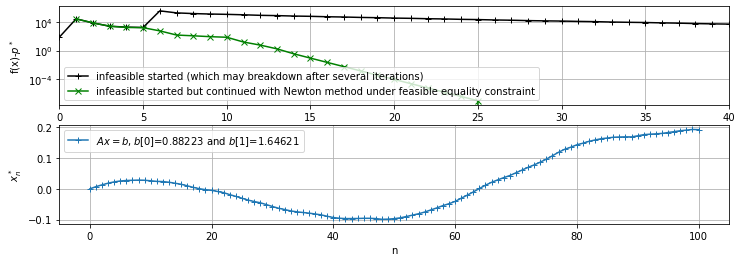

In [31]:
if __name__ == "__main__":
    solve_minimum_length_piecewise_curve_problem(n=100, m=2, seed=2)


Info: infeasible start Newton method interrupted.


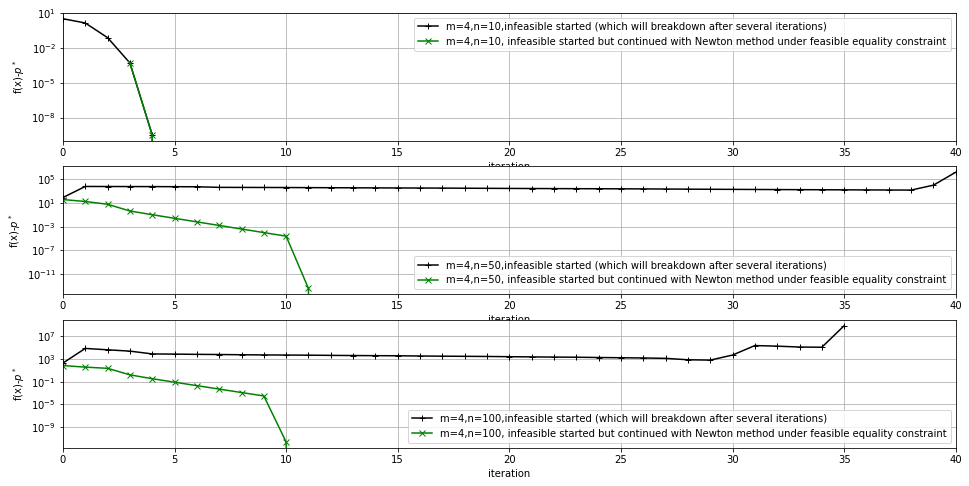

In [32]:
if __name__ == "__main__":
    solve_minimum_length_piecewise_curve_problem_fixed_m_diff_n(n_s=[10, 50, 100], m=4, seed=2)